# Logistic Regression with a Hidden Layer

Open in [Google Colab](https://colab.research.google.com/github/febse/ta2025/blob/main/03-06-ANN-Logistic-Regression.ipynb)

Until now we have used neural networks for regression. The loss function that we used for training was the MSE (Mean Squared Error). The standard loss function for classification is the Cross-Entropy Loss (also known as Log Loss). In this chapter we first understand what it is and why it is preferred to the MSE, and then build a network with a hidden layer for classification with two classes. The next chapter extends it to more than two classes.

Throughout this chapter we use the notation of the previous chapters: observations are the **rows** of the data matrix $X$ ($n \times p$), every layer multiplies from the right (e.g. $X W_h + b_h$), $H$ denotes the net values (pre-activations) of a hidden layer, $Z = \varphi(H)$ its activations, and the output layer is indexed by $o$ ($W_o$, $b_o$). The net value of the output layer (the *logit*) is denoted $O$.

## Entropy and Cross-Entropy

In evaluating a model's accuracy, we need a measure between our model's prediction and a perfect (out-of-sample) prediction. This measure should be able to account for the fact that some outcomes (targets) are easier to predict than others. Consider the task of predicting the weather (sunshine/rain) in a desert, where it almost never rains. A model that always predicts sunshine will be correct most of the time, but it is not a very useful model as you will always be surprised when it rains.

The *entropy* of a distribution is a measure of its uncertainty that has four properties

- It is **zero** if the distribution is degenerate (i.e. the outcome is always sunshine)
- It is **continuous**, so a small change in the distribution will result in a small change in the entropy
- It is **higher** for distributions which can produce **more outcomes** than for distributions that can produce fewer outcomes
- It is **additive**, so the entropy of a distribution is the sum of the entropies of its components. This means that if we first measure the uncertainty about being male/female and then measure the uncertainty about being a soccer fan or not, the uncertainty of the combinations (male/soccer fan, male/not soccer fan, female/soccer-fan, female/not soccer fan) should the sum of the two uncertainties.

It is easy to show that the entropy defined as the expected value of the log-probabilities of the outcomes satisfies these four properties.

$$
H(P) = -\sum_{k} p_k \log p_k = \mathbb{E}\left[-\log p_K\right]
$$

where $K$ is a random outcome drawn from $P$ (we use the natural logarithm throughout).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

p0 = np.array([1])

p1 = np.array([1/2, 1/2])

p2 = np.array([1/100, 99/100])

p3 = np.array([1/3, 1/3, 1/3])

H_p0 = - np.sum(p0 * np.log(p0))
print(f"H_p0: {H_p0:.4f}")

H_p1 = - np.sum(p1 * np.log(p1))
print(f"H_p1: {H_p1:.4f}")

H_p2 = - np.sum(p2 * np.log(p2))
print(f"H_p2: {H_p2:.4f}")

H_p3 = - np.sum(p3 * np.log(p3))
print(f"H_p3: {H_p3:.4f}")

H_p0: -0.0000
H_p1: 0.6931
H_p2: 0.0560
H_p3: 1.0986


In [2]:
# no-ex-class
# Example with DEPENDENT variables
# Strong dependence: Soccer fans tend to be female

# Marginal distributions
p_female = 0.4
p_male = 1 - p_female
p_gender = np.array([p_male, p_female])

p_fan = 0.06 + 0.32  # marginal probability of being a fan (must match the joint table below)
p_not_fan = 1 - p_fan
p_soccer = np.array([p_fan, p_not_fan])

# DEPENDENT joint distribution (not independent)
# Males: mostly NOT fans (90% not fans)
# Females: mostly fans (80% fans)
p_joint_dependent = np.array([
    0.06,   # Male & Fan (10% of 60%)
    0.54,   # Male & Not Fan (90% of 60%)
    0.32,   # Female & Fan (80% of 40%)
    0.08    # Female & Not Fan (20% of 40%)
])

p_joint_independent = np.array([
    p_male * p_fan,
    p_male * p_not_fan,
    p_female * p_fan,
    p_female * p_not_fan
])

def entropy(p):
    """Calculate entropy, handling zero probabilities"""
    p = p[p > 0]
    return -np.sum(p * np.log(p))

H_gender = entropy(p_gender)
H_soccer = entropy(p_soccer)
H_joint_dependent = entropy(p_joint_dependent)
H_joint_independent = entropy(p_joint_independent)

print(f"H(Gender) = {H_gender:.4f}")
print(f"H(Soccer Fan) = {H_soccer:.4f}")
print(f"H(Gender) + H(Soccer) = {H_gender + H_soccer:.4f}")
print(f"H(Gender, Soccer) (independent) = {H_joint_independent:.4f}")
print(f"H(Gender, Soccer) (dependent) = {H_joint_dependent:.4f}")
# For dependent variables H(joint) < H(Gender) + H(Soccer); equality holds only under independence

H(Gender) = 0.6730
H(Soccer Fan) = 0.6641
H(Gender) + H(Soccer) = 1.3371
H(Gender, Soccer) (independent) = 1.3371
H(Gender, Soccer) (dependent) = 1.0682


So the entropy gives us the uncertainty when predicting outcomes using the true distribution (in other words: how difficult it is to predict values from this distribution). When we build prediction models, however, we don't know the distribution generating the outcomes. Instead, we rely on the model to provide probabilities that we hope are close to the true probabilities. 

We can ask: how much does the uncertainty increase if we use a different (from P) distribution  instead of the true probabilities to predict the outcomes? This is the *cross-entropy*.

$$
H(P, Q) = -\sum_{k} p_k \log q_k
$$

It can also be decomposed into the entropy of the true distribution and the Kullback-Leibler divergence between the true distribution and the model distribution.

$$
H(P, Q) = H(P) + \text{KL}(P, Q)
$$

In the above expression, $H(P)$ is the entropy of the data-generating distribution, and $\text{KL}(P, Q)$ is the Kullback-Leibler divergence between the data-generating distribution and the model distribution. The KL divergence is always non-negative, and it is zero if the two distributions are identical. Therefore, the cross-entropy is always greater than or equal to the entropy of the data-generating distribution.

$$
\text{KL}(P, Q) = \sum_{k} p_k (\log p_k - \log q_k) = \sum_{k} p_k \log \frac{p_k}{q_k}
$$

The KL-divergence describes how different P and Q are on average (in units of entropy). You have likely encountered a scaled version of it when studying generalized linear models (GLM) under the name of *deviance*. The deviance is the KL-divergence between the data-generating distribution and the model distribution, scaled by a factor of two.  

In gradient descent, we want to minimize the cross-entropy between the true distribution (the labels) and the model distribution (the predicted probabilities). Since $H(P)$ does not depend on the model, minimizing the cross-entropy is the same as minimizing the KL divergence. Averaged over the observations, this is the cross-entropy loss:

In [3]:
# no-ex-class
# Difficulty predicting outcomes from P using Q

P_true = np.array([0.7, 0.3])  # True distribution
Q_model1 = np.array([0.4, 0.6])  # Model's predicted distribution
Q_model2 = np.array([0.75, 0.25])  # Another model's predicted distribution

H_P = -np.sum(P_true * np.log(P_true))
H_P_Q1 = -np.sum(P_true * np.log(Q_model1))
H_P_Q2 = -np.sum(P_true * np.log(Q_model2))

print(f"Entropy H(P) = {H_P:.4f}")
print(f"Cross-Entropy H(P, Q1) = {H_P_Q1:.4f}")
print(f"Cross-Entropy H(P, Q2) = {H_P_Q2:.4f}")

Entropy H(P) = 0.6109
Cross-Entropy H(P, Q1) = 0.7947
Cross-Entropy H(P, Q2) = 0.6173


:::{#def-cross-entropy-loss}
## Cross-Entropy Loss

Given $K$ classes and $n$ observations, let $Y$ be the $n \times K$ matrix of one-hot encoded labels and $\hat{Y}$ the $n \times K$ matrix of predicted probabilities (each row sums to one). The cross-entropy loss is

:::{.ex-class}
$$
L = \text{CE} = -\frac{1}{n}\sum_{i=1}^n \sum_{k=1}^K y_{ik} \log \hat{y}_{ik}
$$
:::

Each $y_{ik}$ is 1 if observation $i$ belongs to class $k$ and 0 otherwise, and $\hat{y}_{ik}$ is the predicted probability that observation $i$ belongs to class $k$.

:::

Just like the MSE in the regression chapters, we average over the observations (this is also what `nn.CrossEntropyLoss` and `nn.BCELoss` in PyTorch do by default). Because $y_{ik}$ is 1 only for the true class $c(i)$ of observation $i$, the loss of a single observation is $-\log \hat{y}_{i,c(i)}$: the negative log of the probability that the model assigns to the correct class.

Minimizing the cross-entropy loss is equivalent to maximizing the likelihood of the observed data under the model, assuming that the observations are independent and that each observation follows a categorical distribution with the model probabilities $\hat{y}_{i1}, \ldots, \hat{y}_{iK}$.

:::{#def-categorical-likelihood}
## Categorical Distribution and Likelihood

The categorical distribution generalizes the Bernoulli distribution to $K$ possible outcomes (it is the multinomial distribution with a single trial). For an observation $i$ with class probabilities $\hat{y}_{i1}, \ldots, \hat{y}_{iK}$ (with $\sum_{k=1}^K \hat{y}_{ik} = 1$) the probability of the observed class is

$$
P(Y_i = c(i)) = \prod_{k=1}^K \hat{y}_{ik}^{y_{ik}} = \hat{y}_{i,c(i)}
$$

The likelihood for $n$ independent observations is the product over the observations:

$$
\mathcal{L} = \prod_{i=1}^n \prod_{k=1}^K \hat{y}_{ik}^{y_{ik}}
$$

Taking the logarithm gives the log-likelihood, which is $-n$ times the cross-entropy loss:

$$
\log \mathcal{L} = \sum_{i=1}^n \sum_{k=1}^K y_{ik} \log \hat{y}_{ik} = -n \cdot L
$$

:::

Maximizing $\log \mathcal{L}$ is therefore the same as minimizing $L$.

Consider the following example to illustrate the loss computation. Let's say that we have three classes (A, B, C) and the true labels for four observations are as follows:

| Observation | True Class |
|-------------|------------|
| 1           | A          |
| 2           | C          |
| 3           | B          |
| 4           | A          |

The one-hot encoded matrix $Y$ of the true labels and a matrix $\hat{Y}$ of predicted probabilities (each row sums to one) are defined in the next cell.

The loss of each observation is the negative log of the probability of its true class, and the cross-entropy loss is the average over the observations.

In [4]:
# no-ex-class
# One hot-encoded matrix Y of the true labels

true_labels = np.array([
    [1, 0, 0],  # Observation 1: Class A
    [0, 0, 1],  # Observation 2: Class C
    [0, 1, 0],  # Observation 3: Class B
    [1, 0, 0]   # Observation 4: Class A
])

# Predicted probabilities from the model (matrix Y-hat)

predicted_probs = np.array([
    [0.7, 0.2, 0.1],  # Observation 1
    [0.1, 0.3, 0.6],  # Observation 2
    [0.2, 0.5, 0.3],  # Observation 3
    [0.6, 0.3, 0.1]   # Observation 4
])

# Loss of each observation
cross_entropy_obs = -np.sum(true_labels * np.log(predicted_probs), axis=1)

for i, loss_i in enumerate(cross_entropy_obs, start=1):
    print(f"Cross-Entropy Loss for Observation {i}: {loss_i:.4f}")

# Average over all observations
print(f"Cross-Entropy Loss (mean over observations): {cross_entropy_obs.mean():.4f}")

Cross-Entropy Loss for Observation 1: 0.3567
Cross-Entropy Loss for Observation 2: 0.5108
Cross-Entropy Loss for Observation 3: 0.6931
Cross-Entropy Loss for Observation 4: 0.5108
Cross-Entropy Loss (mean over observations): 0.5179


## Why Cross-Entropy Loss instead of MSE?

Could we simply use the MSE to compare the predicted probabilities $\hat{y}$ with the observed outcomes $y \in \{0, 1\}$? The plot below compares the two losses for an observation with $y = 1$ as a function of the predicted probability $\hat{y}$. The MSE penalty $(1 - \hat{y})^2$ never exceeds 1, no matter how wrong the prediction is. The cross-entropy $-\log \hat{y}$ grows without bound as the model assigns a probability close to zero to the outcome that actually occurred (the model is "infinitely surprised").

There is a second, more important reason that concerns training. Anticipating the next section, the network turns its output $o$ (the *logit*) into a probability with the sigmoid function $\hat{y} = \sigma(o) = \frac{1}{1 + e^{-o}}$, which has the derivative $\sigma'(o) = \sigma(o)(1 - \sigma(o))$. For a single observation, the derivatives of the two losses with respect to the logit $o$ are

$$
\frac{\partial}{\partial o} (y - \hat{y})^2 = -2 (y - \hat{y}) \, \hat{y}(1 - \hat{y})
\qquad\qquad
\frac{\partial}{\partial o} \text{BCE} = -(y - \hat{y})
$$

(the second one is derived below). The MSE gradient contains the factor $\hat{y}(1-\hat{y})$, which is close to zero when the sigmoid is saturated. A confidently wrong prediction ($y = 1$, $\hat{y} \approx 0$) therefore produces an almost vanishing gradient and the model learns very slowly, while the gradient of the cross-entropy is large exactly when the prediction is wrong.

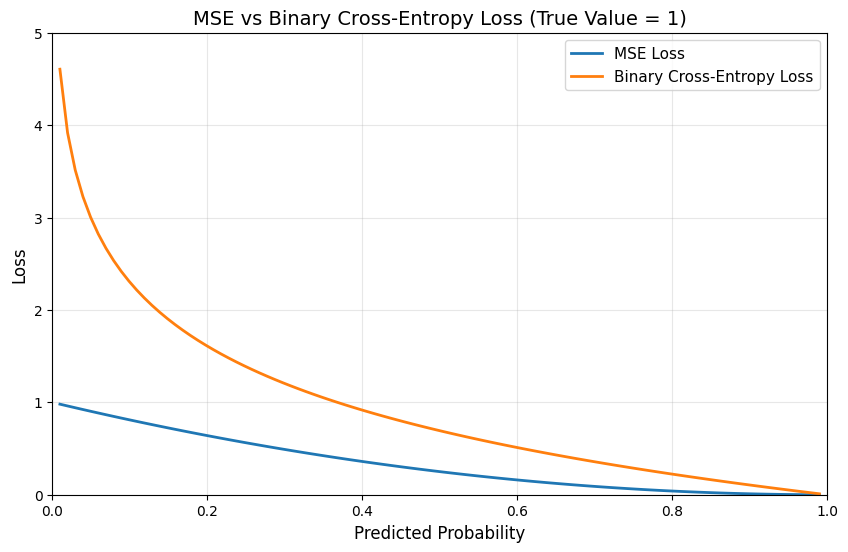

In [5]:
# no-ex-class
# Create range of predicted probabilities
p_hat = np.linspace(0.01, 0.99, 100)

# True value
y_true = 1

# Calculate MSE loss for binary classification (true value = 1)
mse_loss = (y_true - p_hat) ** 2

# Calculate Binary Cross-Entropy loss (true value = 1)
# BCE = -y*log(p_hat) - (1-y)*log(1-p_hat)
# When y=1: BCE = -log(p_hat)
bce_loss = -np.log(p_hat)

# Plot both losses
plt.figure(figsize=(10, 6))
plt.plot(p_hat, mse_loss, label='MSE Loss', linewidth=2)
plt.plot(p_hat, bce_loss, label='Binary Cross-Entropy Loss', linewidth=2)
plt.xlabel('Predicted Probability', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.title('MSE vs Binary Cross-Entropy Loss (True Value = 1)', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xlim(0, 1)
plt.ylim(0, 5)
plt.show()

## Binary Classification

In binary classification, we have only two classes (0 and 1), e.g. default/not default, male/female, yes/no, etc. When making predictions we want our model to output a single probability $\hat{y}$ for class 1, and the probability for class 0 is $1 - \hat{y}$.

We can adapt the network for linear regression for binary classification by passing the output of the network through a **sigmoid** function that maps any real-valued number into the (0, 1) interval, making it suitable for representing probabilities.

In addition we also need to change the loss function from MSE to cross-entropy loss for binary classification.

### Logistic Regression Model

You are likely already familiar with logistic regression models from statistics. In logistic regression, we model the log-odds of the probability of the positive class as a linear function of the input features.

$$
\log \frac{P(Y=1|X)}{P(Y=0|X)} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \ldots + \beta_p x_p
$$

and we assume a Bernoulli distribution for the outcome variable $Y$ with parameter $p = P(Y=1|X)$.

Solving for $P(Y=1|X)$ gives us the logistic (sigmoid) function:

$$
P(Y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \beta_2 x_2 + \ldots + \beta_p x_p)}} = \sigma(\beta_0 + \beta_1 x_1 + \ldots + \beta_p x_p)
$$

where

:::{.ex-class}
$$
\sigma(o) = \frac{1}{1 + e^{-o}}
$$
:::

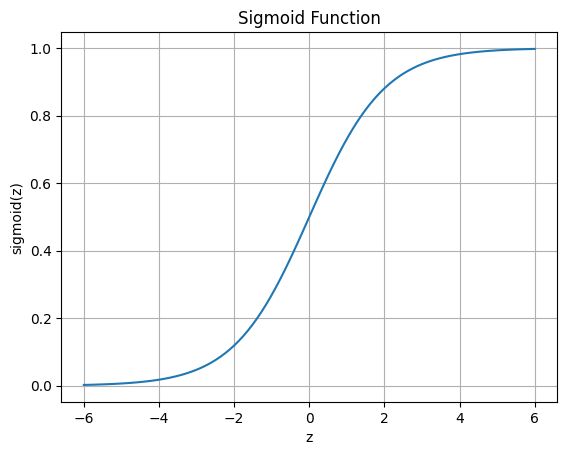

In [6]:
# no-ex-class
# Plot the sigmoid function over -6 to 6

z = np.linspace(-6, 6, 100)
sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)
plt.title("Sigmoid Function")
plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.grid()
plt.show()

In statistics we usually estimate the parameters $\beta$ using maximum likelihood estimation (MLE), which is equivalent to minimizing the cross-entropy loss. For $n$ independent Bernoulli distributed outcomes $y_i \in \{0,1\}$ with success probabilities $\hat{y}_i = P(Y_i = 1 | x_i)$ the likelihood is

$$
\mathcal{L} = \prod_{i=1}^n \hat{y}_i^{y_i} (1 - \hat{y}_i)^{1 - y_i}
$$

Taking the logarithm of the likelihood function gives us the log-likelihood:

$$
\log \mathcal{L} = \sum_{i=1}^n \left( y_i \log \hat{y}_i + (1 - y_i) \log (1 - \hat{y}_i) \right)
$$

## The Logistic Regression as an ANN

Just as with linear regression, the simple logistic regression model maps directly to an ANN with no hidden layers. The input layer consists of the input features, and the output layer consists of a single neuron that applies the sigmoid activation function to produce the predicted probability for class 1.

### Binary Cross-Entropy Loss

The cross-entropy loss for binary classification is known as **binary cross-entropy** (BCE) or log loss. It is the negative (because the convention in optimization is to minimize the loss) average log-likelihood of the Bernoulli distribution, and the special case $K = 2$ of the cross-entropy loss defined above (with $y_{i1} = y_i$ and $y_{i2} = 1 - y_i$).

:::{.ex-class}
$$
L = \text{BCE}(y,\hat{y}) = - \frac{1}{n}\sum_{i=1}^n \left( y_i \log \hat{y}_i + (1 - y_i) \log (1 - \hat{y}_i) \right)
$$
:::

![Binary Classification with ANN](./figures/ann/Binary-Logistic-Regression-Head.png)

The model equation is the same as the logistic regression equation, we only rename the parameters from $\beta_j$ to $w_j$ and the intercept $\beta_0$ to the bias $b$ to align with the ANN notation of the previous chapters.

$$
\begin{align*}
o & = b + w_1 x_1 + w_2 x_2 + \ldots + w_p x_p \\
\hat{y} & = \sigma(o) = \frac{1}{1 + e^{-o}}
\end{align*}
$$

For all $n$ observations at once, with the $n \times p$ data matrix $X$, the $p \times 1$ weight vector $W$ and the bias $b$ added to every row, this reads $O = X W + b$ and $\hat{Y} = \sigma(O)$ (applied element-wise).

:::{.callout-note}
## Logits

We call the input to the final sigmoid function the **logits** $o$ (i.e. this is what the sigmoid maps to probabilities). The logit is the log-odds $\log \frac{\hat{y}}{1 - \hat{y}}$.

:::

### Logistic regression has a linear decision boundary

The logistic regression model classifies an observation as class 1 if $\hat{y} > 0.5$, which is equivalent to $o > 0$, i.e. $b + w_1 x_1 + \ldots + w_p x_p > 0$. The set of points with $o = 0$ is a straight line (a hyperplane for $p > 2$), so logistic regression can only separate classes that are (nearly) *linearly separable*. As in the regression case, the remedy is a hidden layer with a non-linear activation function, and from now on we work directly with such a network.

## Logistic Regression with a Hidden Layer

We add a hidden layer with $k$ neurons and a non-linear activation function $\varphi$ (ReLU, tanh, ...) between the inputs and the output neuron. The network is exactly the regression network of the previous chapter, except that the output is passed through the sigmoid function and that we use the binary cross-entropy loss. With $n$ observations:

| Symbol | Meaning | Shape |
|---|---|---|
| $X$ | data matrix | $n \times p$ |
| $y$ | labels (0 or 1) | $n \times 1$ |
| $W_h$, $b_h$ | hidden layer weights, bias (row vector) | $p \times k$, $1 \times k$ |
| $W_o$, $b_o$ | output layer weights, bias | $k \times 1$, $1 \times 1$ |
| $H$ | hidden net values (pre-activations) | $n \times k$ |
| $Z$ | hidden activations | $n \times k$ |
| $O$ | logits | $n \times 1$ |
| $\hat{y}$ | predicted probabilities of class 1 | $n \times 1$ |

:::{.ex-class}
$$
\begin{align*}
H & = X W_h + b_h \\
Z & = \varphi(H) \\
O & = Z W_o + b_o \\
\hat{y} & = \sigma(O) \\
L & = -\frac{1}{n} \sum_{i=1}^n \left( y_i \log \hat{y}_i + (1 - y_i) \log (1 - \hat{y}_i) \right)
\end{align*}
$$
:::

The bias row vectors are added to every row of the matrices (broadcasting) and $\sigma$ is applied element-wise.

### Gradients

**Step 1: the loss as a function of the logit.** For a single observation the loss is $L_i = -\left( y_i \log \sigma(o_i) + (1 - y_i) \log (1 - \sigma(o_i)) \right)$. Using $\sigma'(o) = \sigma(o)(1 - \sigma(o))$ we get

:::{.ex-class}
$$
\begin{align*}
\frac{\partial L_i}{\partial o_i}
& = -\left( y_i \frac{\sigma(o_i)(1 - \sigma(o_i))}{\sigma(o_i)} - (1 - y_i) \frac{\sigma(o_i)(1 - \sigma(o_i))}{1 - \sigma(o_i)} \right) \\
& = -\left( y_i (1 - \hat{y}_i) - (1 - y_i) \hat{y}_i \right) \\
& = -(y_i - \hat{y}_i)
\end{align*}
$$
:::

The sigmoid derivative cancels with the denominators of the logarithms, and what remains is just the prediction error. Since $L = \frac{1}{n}\sum_i L_i$, we have $\frac{\partial L}{\partial O} = -\frac{1}{n}(y - \hat{y})$ ($n \times 1$).

**Step 2: back-propagation.** From here on the derivation is identical to the regression network of the previous chapter, because the layers below the logit do not know about the sigmoid and the loss. With the error vector $e = y - \hat{y}$:

:::{.ex-class}
$$
\underbrace{\frac{\partial L}{\partial W_o}}_{k \times 1} = -\frac{1}{n} Z^\top e
\qquad
\underbrace{\frac{\partial L}{\partial b_o}}_{1 \times 1} = -\frac{1}{n} \mathbf{1}^\top e
$$
:::

:::{.ex-class}
$$
\underbrace{\frac{\partial L}{\partial H}}_{n \times k} = -\frac{1}{n} \left( e \, W_o^\top \right) \odot \varphi'(H)
\qquad
\underbrace{\frac{\partial L}{\partial W_h}}_{p \times k} = -\frac{1}{n} X^\top \left( \left( e \, W_o^\top \right) \odot \varphi'(H) \right)
\qquad
\underbrace{\frac{\partial L}{\partial b_h}}_{1 \times k} = -\frac{1}{n} \mathbf{1}^\top \left( \left( e \, W_o^\top \right) \odot \varphi'(H) \right)
$$
:::

Compare this with the regression network: the equations are the same, with the factor $-\frac{2}{n}$ replaced by $-\frac{1}{n}$ and the regression error replaced by the classification error $y - \hat{y}$ of the predicted *probability*. The derivatives of the activation functions are listed in the [multi-class chapter](03-07-ANN-Multiclass-Classification.ipynb) (ReLU: $\varphi'(h) = 1$ if $h > 0$ and $0$ otherwise; tanh: $1 - \tanh^2(h)$).

### A small numerical example

We reuse the first layer of the example from the [simple regression chapter](03-04-ANN-Simple-Regression-Hidden-Layer.ipynb), with two observations $x = (4, 2)^\top$, two ReLU neurons, and the output layer

$$
W_o = \begin{bmatrix} 0.8 \\ -1 \end{bmatrix}
\quad
b_o = \begin{bmatrix} -0.1 \end{bmatrix}
\quad
y = \begin{bmatrix} 1 \\ 0 \end{bmatrix}
$$

As before $H = \begin{bmatrix} 1.1 & 0.9 \\ 0.6 & -0.1 \end{bmatrix}$ and $Z = \begin{bmatrix} 1.1 & 0.9 \\ 0.6 & 0 \end{bmatrix}$. The logits and the predicted probabilities are

$$
O = Z W_o + b_o = \begin{bmatrix} -0.12 \\ 0.38 \end{bmatrix}
\qquad
\hat{y} = \sigma(O) \approx \begin{bmatrix} 0.4700 \\ 0.5939 \end{bmatrix}
$$

and the loss is $L = -\frac{1}{2}\left( \log 0.4700 + \log (1 - 0.5939) \right) \approx 0.8280$. The error is $e = y - \hat{y} \approx \begin{bmatrix} 0.5300 \\ -0.5939 \end{bmatrix}$, so

$$
\frac{\partial L}{\partial W_o} = -\frac{1}{2} Z^\top e \approx \begin{bmatrix} -0.1133 \\ -0.2385 \end{bmatrix}
\qquad
\frac{\partial L}{\partial b_o} \approx 0.0320
$$

The back-propagated error is $e W_o^\top \approx \begin{bmatrix} 0.4240 & -0.5300 \\ -0.4751 & 0.5939 \end{bmatrix}$. Multiplying element-wise with $\text{ReLU}'(H) = \begin{bmatrix} 1 & 1 \\ 1 & 0 \end{bmatrix}$ gives $\begin{bmatrix} 0.4240 & -0.5300 \\ -0.4751 & 0 \end{bmatrix}$, and

$$
\frac{\partial L}{\partial W_h} \approx \begin{bmatrix} -0.3728 & 1.0599 \end{bmatrix}
\qquad
\frac{\partial L}{\partial b_h} \approx \begin{bmatrix} 0.0256 & 0.2650 \end{bmatrix}
$$

The next section reproduces these numbers with NumPy, checks the gradient formulas against PyTorch, and trains the network.

## Implementation

We use a data set with two interleaving half-moons: the classes are not linearly separable, so logistic regression without a hidden layer must fail on it.

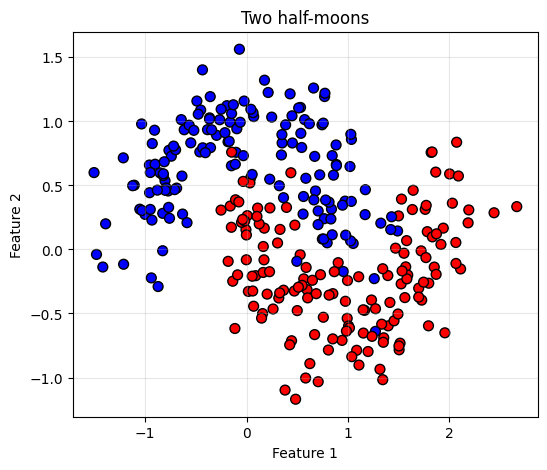

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression

X_moons, y_moons = make_moons(n_samples=300, noise=0.25, random_state=0)
y_moons = y_moons.reshape(-1, 1).astype(float)           # n x 1

plt.figure(figsize=(6, 5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons.ravel(), cmap='bwr', edgecolor='k', s=50)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Two half-moons')
plt.grid(True, alpha=0.3)
plt.show()

### The forward pass and the gradients in NumPy

The functions below implement the equations derived above. First we apply them to the small example.

In [8]:
def sigmoid(O):
    return 1 / (1 + np.exp(-O))

def relu(H):
    return np.maximum(0, H)

def relu_prime(H):
    return (H > 0).astype(float)

def tanh_prime(H):
    return 1 - np.tanh(H) ** 2

def forward(X, params, activation=relu):
    W_h, b_h, W_o, b_o = params
    H = X @ W_h + b_h
    Z = activation(H)
    return H, Z, sigmoid(Z @ W_o + b_o)

def binary_cross_entropy(y, y_hat):
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

def gradients(X, y, params, activation=relu, activation_prime=relu_prime):
    W_h, b_h, W_o, b_o = params
    n = X.shape[0]

    H, Z, y_hat = forward(X, params, activation)
    error = y - y_hat

    dW_o = -(Z.T @ error) / n
    db_o = -error.sum(axis=0, keepdims=True) / n

    Delta = (error @ W_o.T) * activation_prime(H)
    dW_h = -(X.T @ Delta) / n
    db_h = -Delta.sum(axis=0, keepdims=True) / n

    return dW_h, db_h, dW_o, db_o

# The numerical example from above
X_small = np.array([[4.0], [2.0]])
y_small = np.array([[1.0], [0.0]])
params_small = (np.array([[0.25, 0.5]]), np.array([[0.1, -1.1]]),
                np.array([[0.8], [-1.0]]), np.array([[-0.1]]))

_, _, y_hat_small = forward(X_small, params_small)
print("y_hat:", y_hat_small.ravel().round(4))
print("Loss:", round(binary_cross_entropy(y_small, y_hat_small), 4))

for name, grad in zip(["dW_h", "db_h", "dW_o", "db_o"], gradients(X_small, y_small, params_small)):
    print(f"{name}:", grad.round(4).tolist())

y_hat: [0.47   0.5939]
Loss: 0.828
dW_h: [[-0.3728, 1.0599]]
db_h: [[0.0256, 0.265]]
dW_o: [[-0.1133], [-0.2385]]
db_o: [[0.032]]


### Checking the gradients against PyTorch

PyTorch computes the gradients automatically with `loss.backward()`. We use plain tensors for the parameters (the weight of an `nn.Linear(in, out)` layer is the transpose of our weight matrices) and compare the gradients for the ReLU and the tanh activation.

In [9]:
def init_params(n_features, n_hidden, seed=0):
    rng = np.random.default_rng(seed)
    return [
        rng.normal(0, 0.5, (n_features, n_hidden)),   # W_h
        np.zeros((1, n_hidden)),                      # b_h
        rng.normal(0, 0.5, (n_hidden, 1)),            # W_o
        np.zeros((1, 1)),                             # b_o
    ]

params_moons = init_params(n_features=2, n_hidden=8)

activations = {
    "relu": (relu, relu_prime, torch.relu),
    "tanh": (np.tanh, tanh_prime, torch.tanh),
}

X_double = torch.tensor(X_moons)                       # float64 for an accurate comparison
y_double = torch.tensor(y_moons)

for name, (act, act_prime, torch_act) in activations.items():
    grads_numpy = gradients(X_moons, y_moons, params_moons, act, act_prime)

    params_torch = [torch.tensor(p, requires_grad=True) for p in params_moons]
    W_h_t, b_h_t, W_o_t, b_o_t = params_torch
    y_hat_t = torch.sigmoid(torch_act(X_double @ W_h_t + b_h_t) @ W_o_t + b_o_t)
    loss_t = nn.functional.binary_cross_entropy(y_hat_t, y_double)   # mean over observations
    loss_t.backward()

    match = all(np.allclose(g, p.grad.numpy()) for g, p in zip(grads_numpy, params_torch))
    print(f"{name}: gradients match PyTorch autograd: {match}")
    assert match

relu: gradients match PyTorch autograd: True
tanh: gradients match PyTorch autograd: True


### Training

We train the network with plain full-batch gradient descent using only the derived gradients, and compare it with logistic regression without a hidden layer.

Logistic regression (no hidden layer): training accuracy 0.833
Network with a hidden layer (tanh):    training accuracy 0.967, loss 0.1041


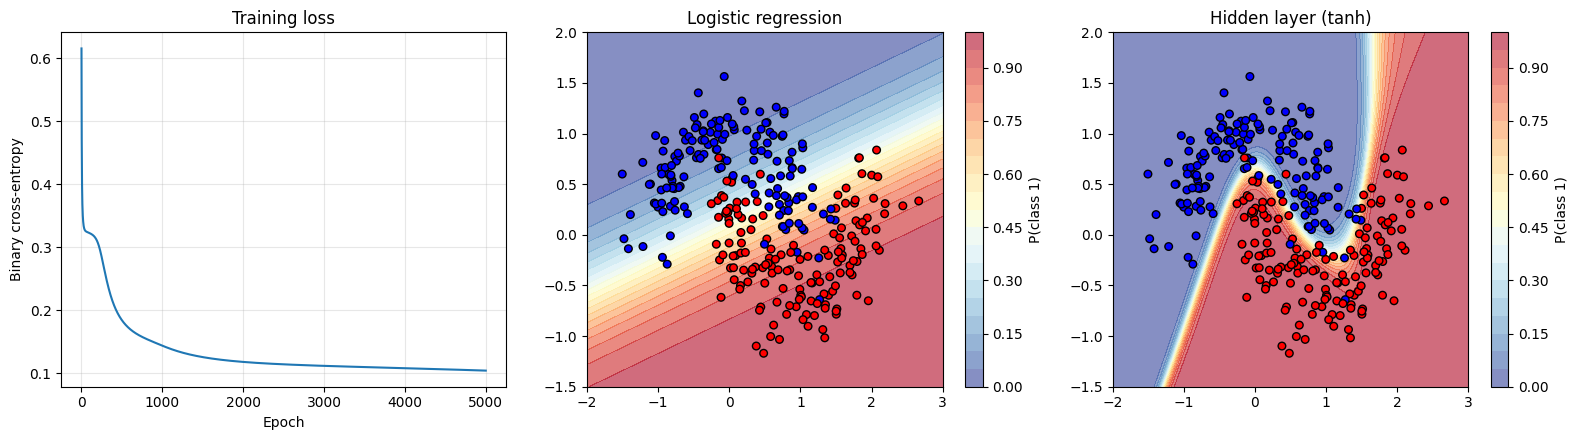

In [10]:
def train(X, y, params, activation, activation_prime, learning_rate=0.5, epochs=5000):
    params = [p.copy() for p in params]
    losses = []
    for epoch in range(epochs):
        grads = gradients(X, y, params, activation, activation_prime)
        for param, grad in zip(params, grads):
            param -= learning_rate * grad              # theta <- theta - eta * dL/dtheta
        losses.append(binary_cross_entropy(y, forward(X, params, activation)[2]))
    return params, losses

trained, losses = train(X_moons, y_moons, params_moons, np.tanh, tanh_prime)
y_hat_nn = forward(X_moons, trained, np.tanh)[2]
accuracy_nn = ((y_hat_nn > 0.5) == y_moons).mean()

logistic = LogisticRegression().fit(X_moons, y_moons.ravel())
accuracy_logistic = logistic.score(X_moons, y_moons.ravel())

print(f"Logistic regression (no hidden layer): training accuracy {accuracy_logistic:.3f}")
print(f"Network with a hidden layer (tanh):    training accuracy {accuracy_nn:.3f}, loss {losses[-1]:.4f}")

# Decision regions
xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(losses)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary cross-entropy')
axes[0].set_title('Training loss')
axes[0].grid(True, alpha=0.3)

panels = [("Logistic regression", logistic.predict_proba(grid)[:, 1]),
          ("Hidden layer (tanh)", forward(grid, trained, np.tanh)[2].ravel())]

for ax, (title, probs) in zip(axes[1:], panels):
    contour = ax.contourf(xx, yy, probs.reshape(xx.shape), levels=20, cmap='RdYlBu_r', alpha=0.6)
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons.ravel(), cmap='bwr', edgecolor='k', s=30)
    ax.set_title(title)
    fig.colorbar(contour, ax=ax, label='P(class 1)')

plt.tight_layout()
plt.show()

### The same model in PyTorch

In PyTorch the network is a sequence of layers. We let the last layer output the logit and use `nn.BCEWithLogitsLoss`, which applies the sigmoid inside the loss in a numerically stable way (the counterpart of `nn.CrossEntropyLoss` in the multi-class case).

In [11]:
torch.manual_seed(0)

X_tensor = torch.tensor(X_moons, dtype=torch.float32)
y_tensor = torch.tensor(y_moons, dtype=torch.float32)

model = nn.Sequential(
    nn.Linear(2, 8),     # X W_h + b_h  (the weight is stored as 8 x 2, the transpose of W_h)
    nn.Tanh(),           # Z = tanh(H)
    nn.Linear(8, 1),     # logits O = Z W_o + b_o
)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(2000):
    loss = criterion(model(X_tensor), y_tensor)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

with torch.no_grad():
    probs = torch.sigmoid(model(X_tensor))
    accuracy = ((probs > 0.5).float() == y_tensor).float().mean()

print(f"Final loss: {loss.item():.4f}, training accuracy: {accuracy.item():.3f}")

Final loss: 0.0895, training accuracy: 0.970
